In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

In [30]:
# 1. Read Dataset
df = pd.read_csv("online_retail_II.csv", encoding="ISO-8859-1")

print("Original Shape:", df.shape)


Original Shape: (525461, 8)


In [31]:
# 2. Data Preprocessing
df = df.dropna(subset=["CustomerID"])

df = df[ ~df["Invoice"].astype(str).str.startswith("C")]

df = df[(df["Quantity"] > 0) &(df["Price"] > 0)]

df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"],format="mixed",errors="coerce")


df["TotalAmount"] = (df["Quantity"] * df["Price"])

In [32]:
# 3. Create RFM Features
reference_date = (df["InvoiceDate"].max() + pd.Timedelta(days=1))

rfm = df.groupby("CustomerID").agg({
    "InvoiceDate":
        lambda x:
        (reference_date - x.max()).days,
    "Invoice": "nunique",
    "TotalAmount": "sum"
})

rfm.columns = ["Recency","Frequency","Monetary"]

print("\nRFM Data:")
print(rfm.head())


RFM Data:
            Recency  Frequency  Monetary
CustomerID                              
12346.0         165         11    372.86
12347.0           3          2   1323.32
12348.0          74          1    222.16
12349.0          43          3   2671.14
12351.0          11          1    300.93


In [33]:
# 4. Log Transformation
X = np.log1p(rfm)

In [34]:
# 5. Standardization
X = StandardScaler().fit_transform(X)

In [35]:
# 6. Sample Customers
# Manual hierarchical clustering is expensive
n = min(10, len(X))

np.random.seed(42)

idx = np.random.choice( len(X), n, replace=False)

X = X[idx]

In [36]:
# 7. Distance Matrix
def distance_matrix(X):

    n = len(X)
    D = np.zeros((n, n))

    for i in range(n):
        for j in range(i + 1, n):
            d = np.sqrt(np.sum((X[i] - X[j]) ** 2))
            D[i, j] = d
            D[j, i] = d
    return D

In [37]:
# 8. Hierarchical Clustering
def hierarchical(X):

    n = len(X)
    D = distance_matrix(X)

    clusters = [[i] for i in range(n)]
    ids = list(range(n))

    merges = []
    next_id = n

    while len(clusters) > 1:

        minimum = float("inf")
        a = b = None

        for i in range(len(clusters)):
            for j in range(i + 1,
                           len(clusters)):

                d = min(
                    D[p, q]
                    for p in clusters[i]
                    for q in clusters[j]
                )

                if d < minimum:
                    minimum = d
                    a, b = i, j

        merges.append([ids[a],ids[b],minimum,len(clusters[a])+len(clusters[b])])

        new_cluster = (clusters[a] + clusters[b])

        if a > b:
            a, b = b, a

        clusters.pop(b)
        clusters.pop(a)

        ids.pop(b)
        ids.pop(a)

        clusters.append(new_cluster)
        ids.append(next_id)

        next_id += 1

    return np.array(merges)


merges = hierarchical(X)

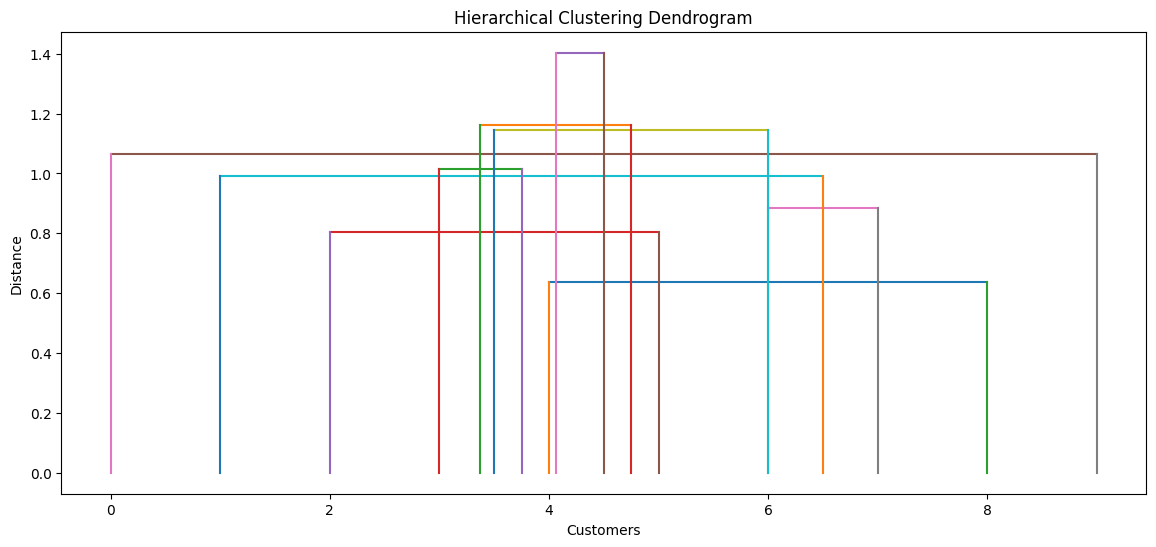

In [38]:
# 9. Draw Dendrogram
def dendrogram(merges, n):

    pos = {i: i for i in range(n)}
    cid = n

    plt.figure(figsize=(14, 6))

    for m in merges:

        a = int(m[0])
        b = int(m[1])
        h = m[2]

        x1 = pos[a]
        x2 = pos[b]

        plt.plot([x1, x2],[h, h])

        plt.plot([x1, x1],[0, h])

        plt.plot([x2, x2],[0, h])

        pos[cid] = (x1 + x2) / 2
        cid += 1

    plt.title("Hierarchical Clustering Dendrogram")

    plt.xlabel("Customers")
    plt.ylabel("Distance")

    plt.show()
dendrogram(merges, len(X))

In [39]:
# 10. Generate Clusters
def get_clusters(merges, n, k):

    clusters = {i: [i] for i in range(n)}

    cid = n

    for m in merges[:n-k]:

        a = int(m[0])
        b = int(m[1])

        clusters[cid] = (clusters[a] + clusters[b])

        del clusters[a]
        del clusters[b]

        cid += 1

    labels = np.zeros(n, dtype=int)

    for label, members in enumerate(
        clusters.values()
    ):
        for i in members:
            labels[i] = label

    return labels

In [40]:
# 11. Find Optimal K
scores = []

for k in range(2, 8):

    labels = get_clusters(merges, len(X), k)

    score = silhouette_score(X, labels)

    scores.append(score)

    print("K =", k," Silhouette Score =",round(score, 4))

K = 2  Silhouette Score = 0.4704
K = 3  Silhouette Score = 0.4264
K = 4  Silhouette Score = 0.351
K = 5  Silhouette Score = 0.2613
K = 6  Silhouette Score = 0.0626
K = 7  Silhouette Score = 0.0865


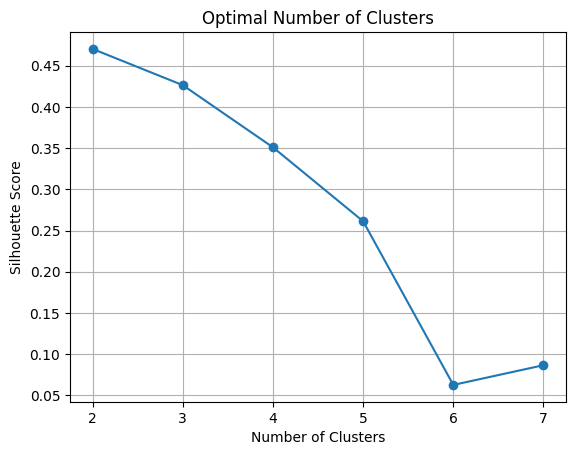

In [41]:
# 12. Plot Scores
plt.plot(range(2, 8),scores,marker="o")

plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.title("Optimal Number of Clusters")

plt.grid()
plt.show()

In [42]:
# 13. Optimal K
optimal_k = range(2, 8)[np.argmax(scores)]

print("\nOptimal Number of Clusters:", optimal_k)


Optimal Number of Clusters: 2
